In [2]:
import pandas as pd

test_set1 = pd.read_csv("test_set1.csv")

X_test_set1 = test_set1.drop(columns=["Target"])
y_test_set1 = test_set1["Target"]

test_set2 = pd.read_csv("test_set2.csv")

X_test_set2 = test_set2.drop(columns=["Target"])
y_test_set2 = test_set2["Target"]

test_set3 = pd.read_csv("test_set3.csv")

X_test_set3 = test_set3.drop(columns=["Target"])
y_test_set3 = test_set3["Target"]

In [3]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.inspection import permutation_importance

# Load the saved model bundles
dt_bundle = joblib.load("decision_tree_set2_ffs.joblib")
knn_bundle = joblib.load("knn_set1_ffs.joblib")
lr_bundle = joblib.load("logistic_regression_set1_ffs.joblib")
rf_bundle = joblib.load("random_forest_set3_ffs.joblib")
svm_bundle = joblib.load("svm_set1.joblib")

# Model name -> saved bundle and matching test data
model_info = {
    "Decision Tree (Set 2 FFS)": (
        dt_bundle, X_test_set2, y_test_set2
    ),
    "KNN (Set 1 FFS)": (
        knn_bundle, X_test_set1, y_test_set1
    ),
    "Logistic Regression (Set 1 FFS)": (
        lr_bundle, X_test_set1, y_test_set1
    ),
    "Random Forest (Set 3 FFS)": (
        rf_bundle, X_test_set3, y_test_set3
    ),
    "SVM (Set 1)": (
        svm_bundle, X_test_set1, y_test_set1
    )
}

print("All saved models loaded.")


All saved models loaded.


In [4]:

permutation_results = {}

for model_name, (bundle, X_test, y_test) in model_info.items():

    model = bundle["model"]

    # FFS bundles use selected_features; the SVM bundle uses feature_names
    feature_names = bundle.get(
        "selected_features",
        bundle.get("feature_names")
    )

    if feature_names is None:
        raise ValueError(
            f"No saved feature list found for {model_name}"
        )

    # Use the exact features and order required by the fitted model
    missing = set(feature_names) - set(X_test.columns)
    if missing:
        raise ValueError(
            f"{model_name}: missing test features: {missing}"
        )

    X_eval = X_test[feature_names]

    result = permutation_importance(
        model,
        X_eval,
        y_test,
        scoring="f1_macro",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance Mean": result.importances_mean,
        "Importance Std": result.importances_std
    }).sort_values(
        "Importance Mean",
        ascending=False
    ).reset_index(drop=True)

    permutation_results[model_name] = importance_df

    print(f"\n{model_name}")
    display(importance_df.round(4))



Decision Tree (Set 2 FFS)


,Feature,Importance Mean,Importance Std
0,Major_Axis_Length,0.3914,0.0127
1,Perimeter,0.0058,0.0036
2,Eccentricity,0.0015,0.0015



KNN (Set 1 FFS)


,Feature,Importance Mean,Importance Std
0,Major_Axis_Length,0.2637,0.0170
1,Perimeter,0.0899,0.0126



Logistic Regression (Set 1 FFS)


,Feature,Importance Mean,Importance Std
0,Convex_Area,0.5586,0.0124
1,Major_Axis_Length,0.1500,0.0147
2,Area,0.1205,0.0118
3,Minor_Axis_Length,0.0805,0.0109
4,Perimeter,0.0298,0.0069



Random Forest (Set 3 FFS)


,Feature,Importance Mean,Importance Std
0,Major_Axis_Length,0.4075,0.0148
1,Extent,-0.0000,0.0018
2,Minor_Axis_Length,-0.0032,0.0024



SVM (Set 1)


,Feature,Importance Mean,Importance Std
0,Convex_Area,0.5302,0.0117
1,Major_Axis_Length,0.3075,0.0163
2,Area,0.1011,0.0142
3,Minor_Axis_Length,0.0673,0.0102
4,Perimeter,0.0204,0.0066
5,Extent,0.0006,0.0032
6,Eccentricity,-0.0005,0.0036


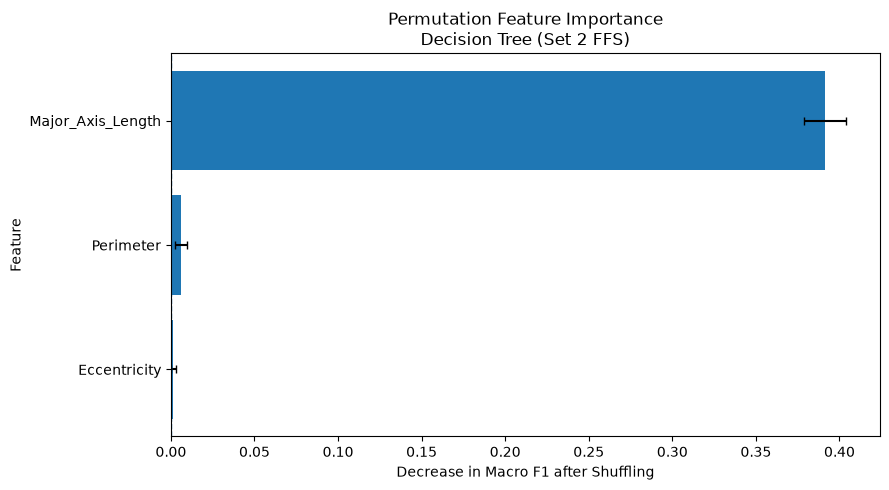

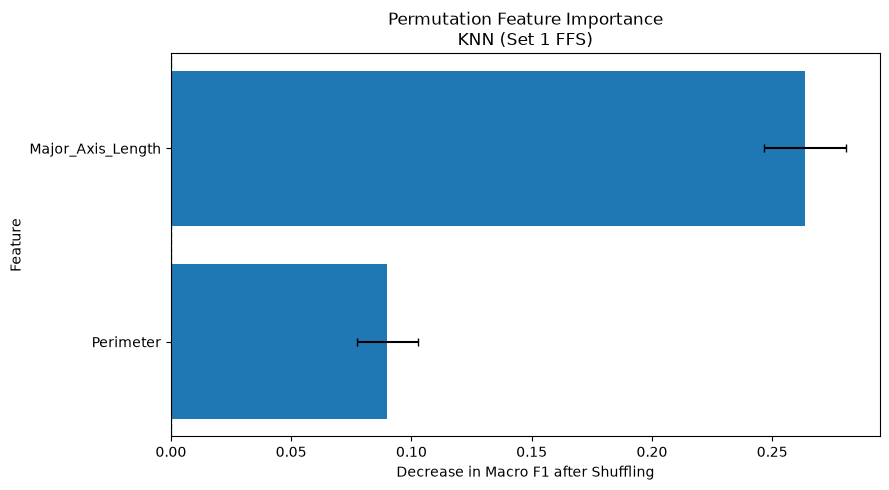

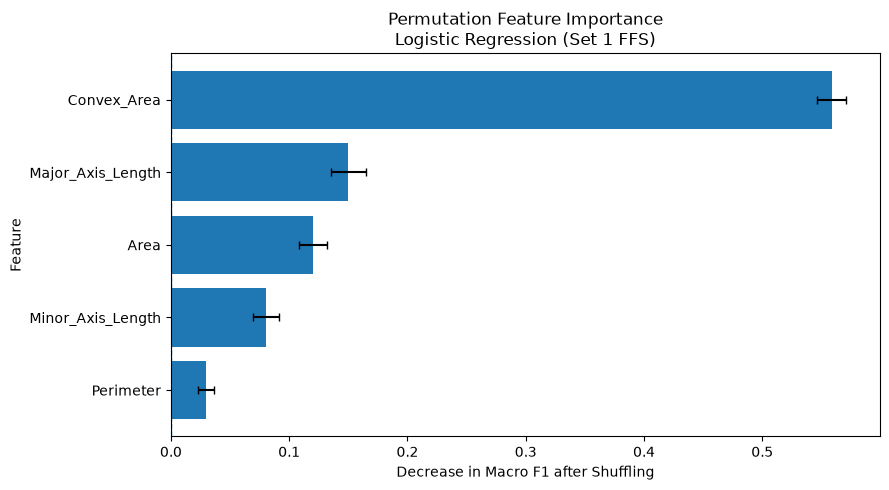

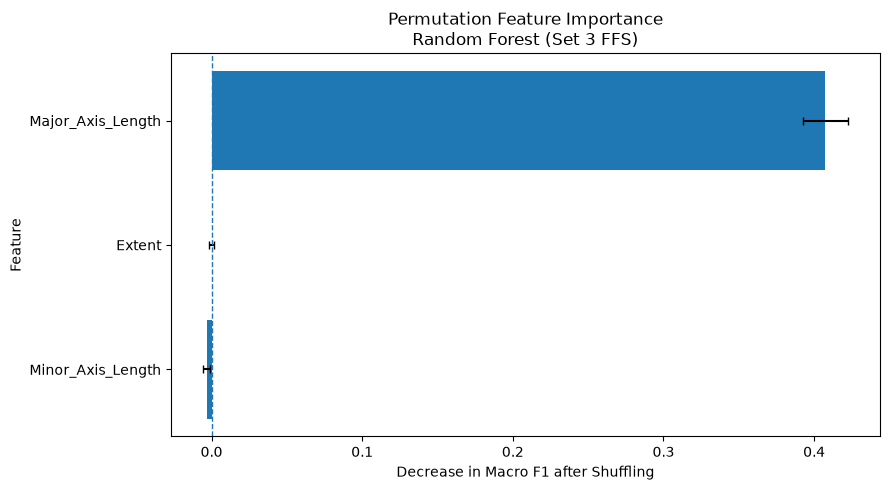

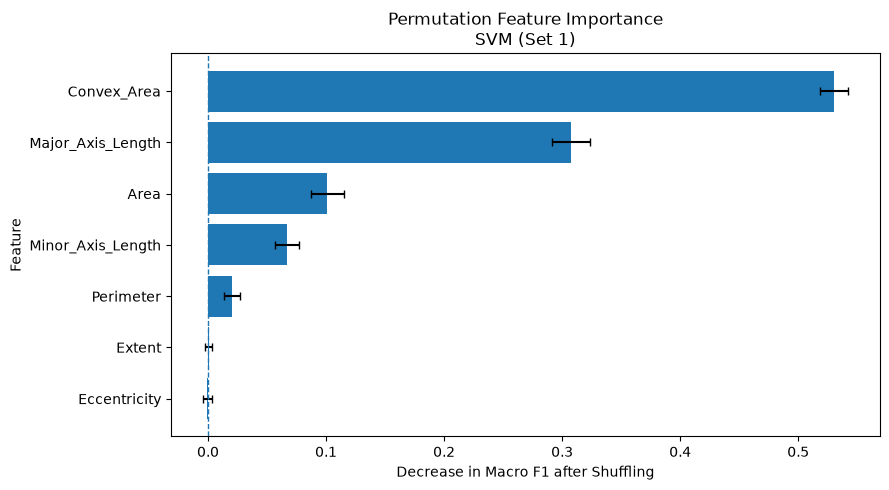

In [5]:

for model_name, importance_df in permutation_results.items():

    plot_df = importance_df.sort_values("Importance Mean")

    plt.figure(figsize=(9, 5))

    plt.barh(
        plot_df["Feature"],
        plot_df["Importance Mean"],
        xerr=plot_df["Importance Std"],
        capsize=3
    )

    plt.axvline(0, linestyle="--", linewidth=1)

    plt.xlabel("Decrease in Macro F1 after Shuffling")
    plt.ylabel("Feature")
    plt.title(f"Permutation Feature Importance\n{model_name}")

    plt.tight_layout()
    plt.show()


In [6]:

summary_rows = []

for model_name, importance_df in permutation_results.items():

    top_feature = importance_df.iloc[0]

    summary_rows.append({
        "Model": model_name,
        "Most Important Feature": top_feature["Feature"],
        "Importance Mean": top_feature["Importance Mean"],
        "Importance Std": top_feature["Importance Std"]
    })

importance_summary = pd.DataFrame(summary_rows)

display(
    importance_summary.style.format({
        "Importance Mean": "{:.4f}",
        "Importance Std": "{:.4f}"
    })
)


,Model,Most Important Feature,Importance Mean,Importance Std
0,Decision Tree (Set 2 FFS),Major_Axis_Length,0.3914,0.0127
1,KNN (Set 1 FFS),Major_Axis_Length,0.2637,0.0170
2,Logistic Regression (Set 1 FFS),Convex_Area,0.5586,0.0124
3,Random Forest (Set 3 FFS),Major_Axis_Length,0.4075,0.0148
4,SVM (Set 1),Convex_Area,0.5302,0.0117


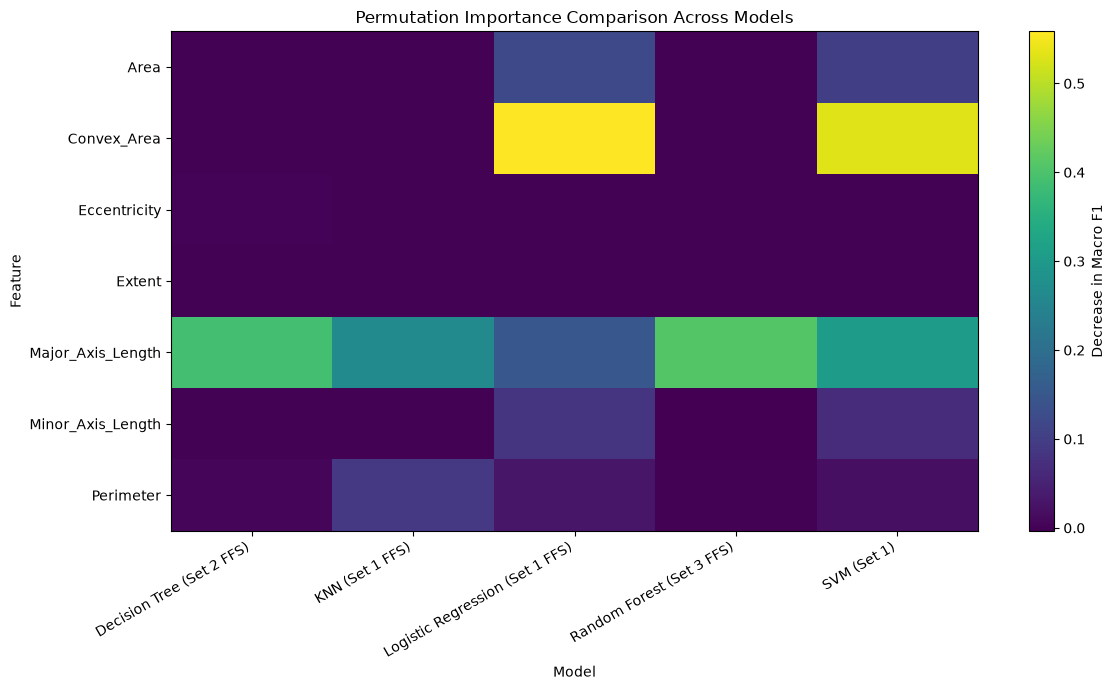

In [7]:

# Combine results from all models
combined_importance = pd.concat(
    [
        df.assign(Model=model_name)
        for model_name, df in permutation_results.items()
    ],
    ignore_index=True
)

importance_matrix = combined_importance.pivot(
    index="Feature",
    columns="Model",
    values="Importance Mean"
)

plt.figure(figsize=(12, 7))

plt.imshow(
    importance_matrix.fillna(0).values,
    aspect="auto"
)

plt.xticks(
    range(len(importance_matrix.columns)),
    importance_matrix.columns,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(importance_matrix.index)),
    importance_matrix.index
)

plt.colorbar(label="Decrease in Macro F1")
plt.title("Permutation Importance Comparison Across Models")
plt.xlabel("Model")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



Decision Tree (Set 2 FFS) — Built-in Feature Importance


,Feature,Built-in Importance
0,Major_Axis_Length,0.9232
1,Perimeter,0.0658
2,Eccentricity,0.0110


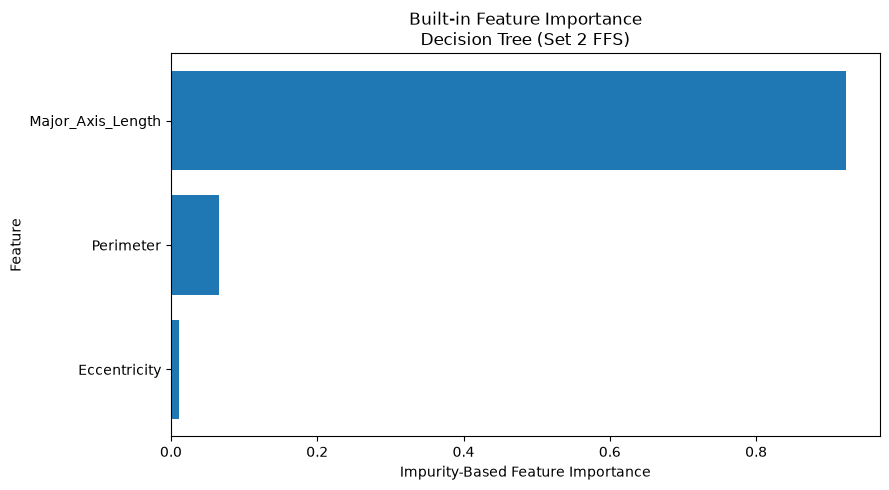


Random Forest (Set 3 FFS) — Built-in Feature Importance


,Feature,Built-in Importance
0,Major_Axis_Length,0.7851
1,Minor_Axis_Length,0.1309
2,Extent,0.0840


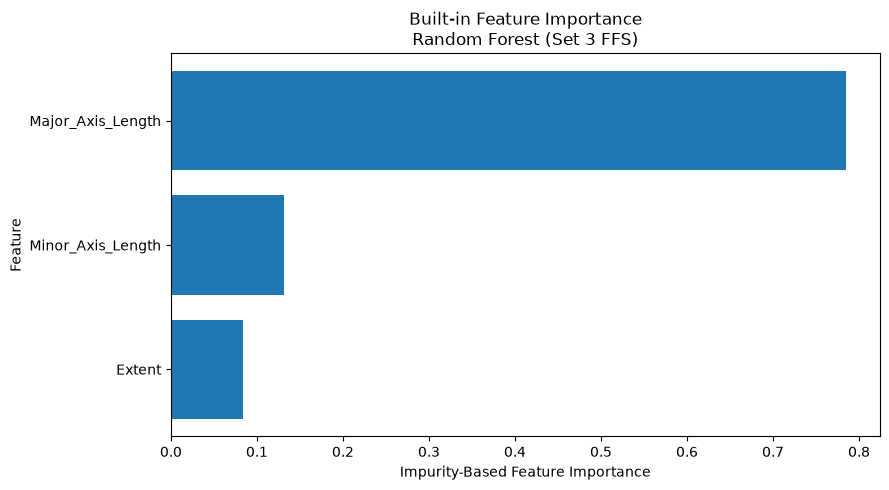

In [9]:

tree_models = {
    "Decision Tree (Set 2 FFS)": dt_bundle,
    "Random Forest (Set 3 FFS)": rf_bundle
}

for model_name, bundle in tree_models.items():

    model = bundle["model"]

    feature_names = bundle.get(
        "selected_features",
        bundle.get("feature_names")
    )

    # Extract the final estimator from the Pipeline
    if hasattr(model, "named_steps"):
        final_estimator = model.named_steps["model"]
    else:
        final_estimator = model

    # Check whether the estimator supports built-in importance
    if not hasattr(final_estimator, "feature_importances_"):
        print(f"{model_name} does not support built-in feature importance.")
        continue

    importance_values = final_estimator.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Built-in Importance": importance_values
    }).sort_values(
        "Built-in Importance",
        ascending=False
    ).reset_index(drop=True)

    print(f"\n{model_name} — Built-in Feature Importance")
    display(importance_df.round(4))

    plot_df = importance_df.sort_values("Built-in Importance")

    plt.figure(figsize=(9, 5))
    plt.barh(
        plot_df["Feature"],
        plot_df["Built-in Importance"]
    )

    plt.xlabel("Impurity-Based Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"Built-in Feature Importance\n{model_name}")
    plt.tight_layout()
    plt.show()


## Conclusion: Feature Importance Analysis

Feature importance analysis was performed to understand how the input features contribute to the predictions of the five trained classification models: Decision Tree, K-Nearest Neighbors (KNN), Logistic Regression, Random Forest, and Support Vector Machine (SVM).

Permutation importance was used as the common evaluation method for all five models. It measures the reduction in macro F1-score when an individual feature is randomly shuffled. A larger positive importance score indicates that the model relies more heavily on that feature to maintain its predictive performance. Features with importance values close to zero have a smaller measured impact, while negative values may indicate that shuffling the feature slightly improved performance in the evaluation.

In addition, built-in feature importance was extracted from the Decision Tree and Random Forest models. These values represent the contribution of features to impurity reduction during tree construction. However, built-in importance and permutation importance measure different aspects of feature relevance, so their values should not be directly compared.

The analysis provides a way to identify which features are most influential for each model and whether different algorithms rely on similar or different features when classifying rice varieties. Since the models use different feature subsets selected through Forward Feature Selection (FFS), some features are absent from certain models. A feature not included in a model should not be interpreted as having zero importance; it was simply not used by that model.

Overall, feature importance improves model interpretability and helps assess the usefulness of the selected features. However, importance scores indicate predictive contribution rather than causation. Furthermore, correlated features may share predictive information, which can affect their individual importance scores. Therefore, these results should be interpreted alongside the test-set performance metrics and the feature-selection results when drawing conclusions about the final rice classification model.
